# Brain Tumor MRI Classification (Mendeley dataset)

Classify brain MRI images into four classes: **glioma**, **meningioma**, **pituitary** tumor, or **no tumor**.

- Dataset: [Brain Tumor MRI Dataset (Glioma, Meningioma, Pituitary, No Tumor)](https://data.mendeley.com/datasets/zwr4ntf94j) on Mendeley Data
- Model: MobileNetV2 (pretrained on ImageNet) + a small classification head
- Framework: TensorFlow / Keras

> Turn on a GPU first: **Runtime → Change runtime type → T4 GPU**.

*Educational project only. Not for medical use.*

### Which dataset version?
Mendeley keeps several versions of this dataset. Version 1 (12,064 images, 80/20 split) may contain duplicate images shared between train and test, which inflates accuracy. Later versions were rebuilt with de-duplication and a train/val/test split. **Prefer the latest version.** This notebook works with either layout, and section 3 checks for exact duplicates between splits.

## 1. Get the data into Colab

1. On the Mendeley page, download the `.zip` file.
2. Put it in Colab using either option:
   - **Drive (recommended for a 240 MB file):** upload the zip to your Google Drive, then run the Drive cell below.
   - **Direct upload:** open the Files panel (folder icon, left side), drag the zip into `/content`.
3. Set `ZIP_PATH` in the next cell to the zip's location.

In [1]:
ZIP_PATH = "/content/Brain_Tumor_MRI_Dataset_Final.zip"

## 2. Setup and unzip

In [2]:
import os, glob, zipfile, hashlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

EXTRACT_DIR = "/content/data"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(EXTRACT_DIR)

# some uploads contain a zip inside the zip
for inner in glob.glob(EXTRACT_DIR + "/**/*.zip", recursive=True):
    with zipfile.ZipFile(inner) as z:
        z.extractall(os.path.dirname(inner))

print("Extracted to", EXTRACT_DIR)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Extracted to /content/data


## 3. Find the train / val / test folders

In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png")

def find_split(names):
    """Find a folder with one of these names that contains class subfolders of images."""
    for root, dirs, _ in os.walk(EXTRACT_DIR):
        if "__MACOSX" in root:
            continue
        for d in dirs:
            if d.lower() in names:
                p = os.path.join(root, d)
                subs = [s for s in os.listdir(p) if os.path.isdir(os.path.join(p, s))]
                if subs and any(f.lower().endswith(IMG_EXT)
                                for f in os.listdir(os.path.join(p, subs[0]))):
                    return p
    return None

train_dir = find_split({"train", "training"})
val_dir   = find_split({"val", "valid", "validation"})
test_dir  = find_split({"test", "testing"})

print("train:", train_dir)
print("val:  ", val_dir)
print("test: ", test_dir)
assert train_dir and test_dir, "Could not find train/test folders - check the unzipped structure"

for name, d in [("train", train_dir), ("val", val_dir), ("test", test_dir)]:
    if d:
        print(f"\n{name}")
        for c in sorted(os.listdir(d)):
            print(f"  {c:20s} {len(os.listdir(os.path.join(d, c)))} images")

train: /content/data/train
val:   /content/data/val
test:  /content/data/test

train
  glioma               1534 images
  meningioma           1035 images
  no_tumor             551 images
  pituitary            1040 images

val
  glioma               329 images
  meningioma           222 images
  no_tumor             118 images
  pituitary            223 images

test
  glioma               328 images
  meningioma           221 images
  no_tumor             118 images
  pituitary            222 images


### Duplicate check
Counts byte-identical images shared between train and test. This only catches exact copies (not slightly edited ones), but any overlap here means your test score is inflated.

In [4]:
def hashes(folder):
    out = set()
    for f in glob.glob(folder + "/**/*", recursive=True):
        if f.lower().endswith(IMG_EXT):
            with open(f, "rb") as fh:
                out.add(hashlib.md5(fh.read()).hexdigest())
    return out

h_train, h_test = hashes(train_dir), hashes(test_dir)
print("unique train images:", len(h_train))
print("unique test images: ", len(h_test))
print("exact duplicates shared by train and test:", len(h_train & h_test))

unique train images: 4160
unique test images:  889
exact duplicates shared by train and test: 0


## 4. Load the data

In [5]:
IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42
keras.utils.set_random_seed(SEED)

opts = dict(image_size=IMG_SIZE, batch_size=BATCH, crop_to_aspect_ratio=True)

if val_dir:
    train_ds = keras.utils.image_dataset_from_directory(train_dir, seed=SEED, **opts)
    val_ds   = keras.utils.image_dataset_from_directory(val_dir, shuffle=False, **opts)
else:
    train_ds = keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="training", seed=SEED, **opts)
    val_ds = keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="validation", seed=SEED, **opts)

test_ds = keras.utils.image_dataset_from_directory(test_dir, shuffle=False, **opts)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 4160 files belonging to 4 classes.
Found 892 files belonging to 4 classes.
Found 889 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


## 5. Look at some images

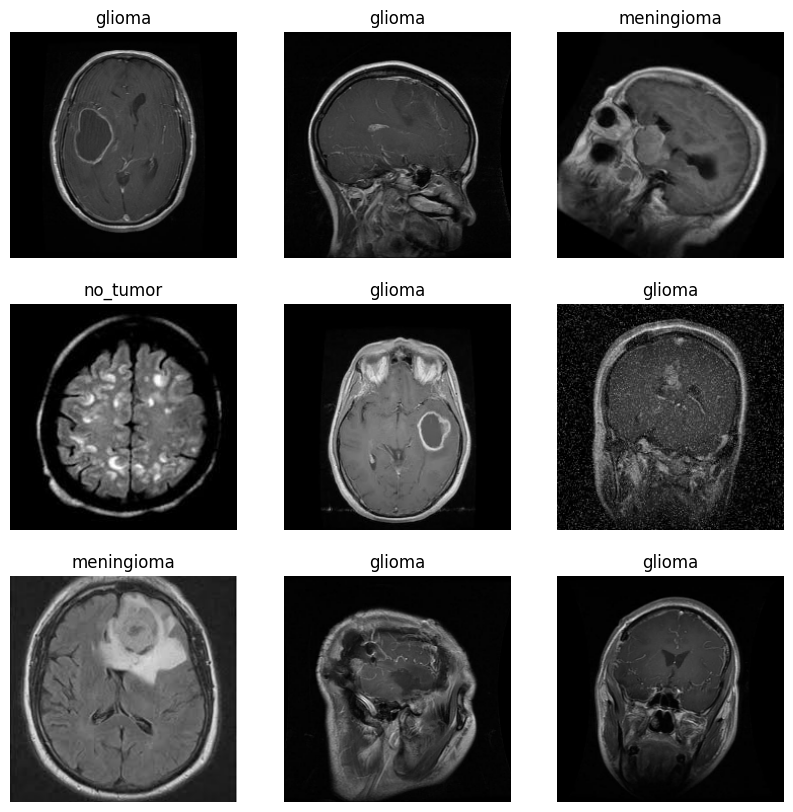

In [6]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

## 6. Build the model

In [7]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
])

base = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Train

In [8]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=15, callbacks=[early_stop])

Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - accuracy: 0.6517 - loss: 0.8566 - val_accuracy: 0.7724 - val_loss: 0.6025
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.7572 - loss: 0.6292 - val_accuracy: 0.7522 - val_loss: 0.6180
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.7844 - loss: 0.5634 - val_accuracy: 0.7825 - val_loss: 0.5428
Epoch 4/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.7962 - loss: 0.5359 - val_accuracy: 0.7825 - val_loss: 0.5404
Epoch 5/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.8046 - loss: 0.5000 - val_accuracy: 0.7915 - val_loss: 0.5166
Epoch 6/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.8055 - loss: 0.5251 - val_accuracy: 0.8094 - val_loss: 0.4717
Epoch 7/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.8132 - loss: 0.4927 - val_accuracy: 0.7948 - val_loss: 0.5194
Epoch 8/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - accuracy: 0.8175 - loss: 0.4969 - v

### Optional: fine-tune the top layers
Run this after the cell above. It usually adds a few points of accuracy. It recompiles with a small learning rate so the pretrained weights aren't destroyed.

In [9]:
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history_ft = model.fit(train_ds, validation_data=val_ds,
                       epochs=15, callbacks=[early_stop])

Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 27s 111ms/step - accuracy: 0.7300 - loss: 0.7261 - val_accuracy: 0.8206 - val_loss: 0.4769
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.7925 - loss: 0.5602 - val_accuracy: 0.8061 - val_loss: 0.5161
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - accuracy: 0.8135 - loss: 0.4932 - val_accuracy: 0.8016 - val_loss: 0.5464


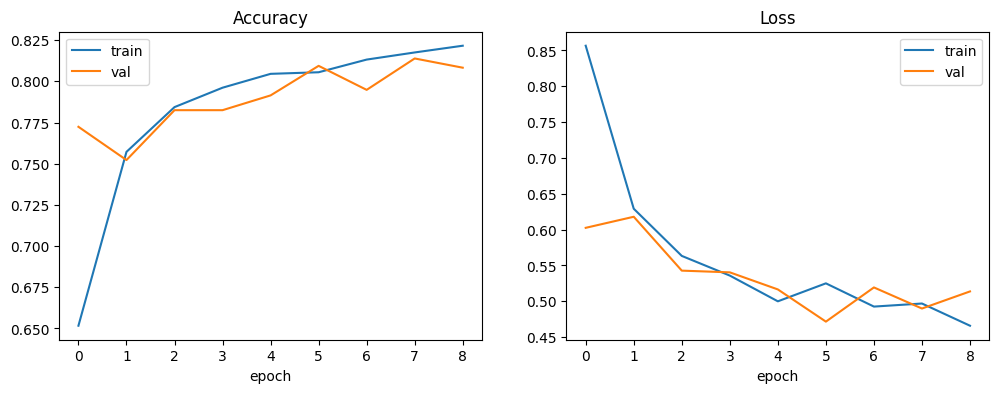

In [10]:
# Training curves (from the first training run)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 8. Evaluate on the test set

train: 0.831250011920929
val:   0.8206278085708618
test:  0.8188976645469666
              precision    recall  f1-score   support

      glioma       0.85      0.84      0.85       328
  meningioma       0.74      0.60      0.66       221
    no_tumor       0.87      0.87      0.87       118
   pituitary       0.81      0.97      0.88       222

    accuracy                           0.82       889
   macro avg       0.82      0.82      0.82       889
weighted avg       0.82      0.82      0.81       889



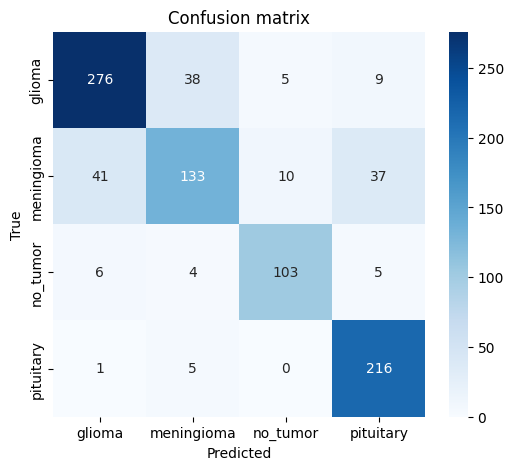

In [11]:
print("train:", model.evaluate(train_ds, verbose=0)[1])
print("val:  ", model.evaluate(val_ds, verbose=0)[1])
print("test: ", model.evaluate(test_ds, verbose=0)[1])

y_true, y_pred = [], []
for x, y in test_ds:
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(model.predict(x, verbose=0), axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.show()

## 9. Predictions on test images

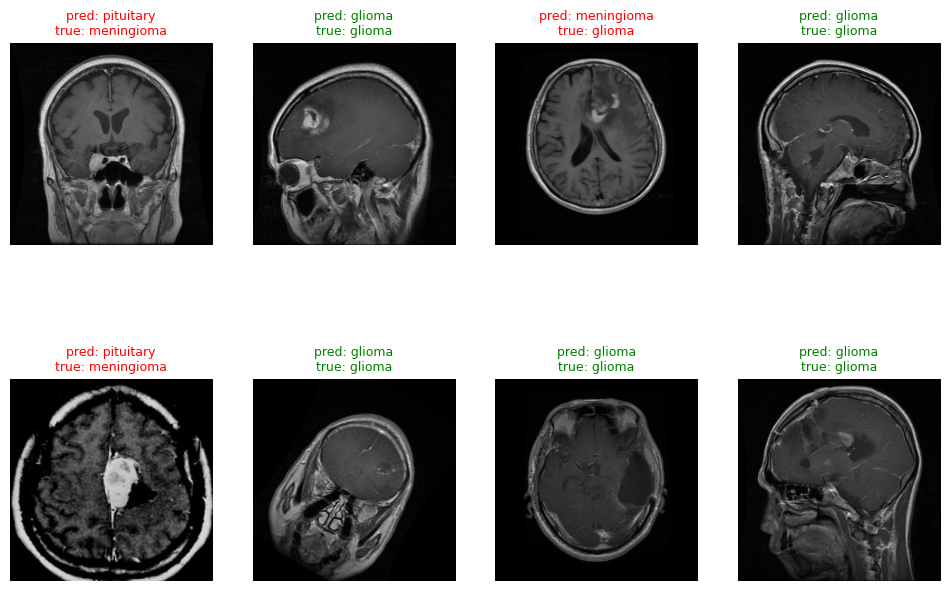

In [12]:
plt.figure(figsize=(12, 8))
for images, labels in test_ds.unbatch().shuffle(400, seed=1).batch(8).take(1):
    probs = model.predict(images, verbose=0)
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred = class_names[np.argmax(probs[i])]
        true = class_names[labels[i]]
        plt.title(f"pred: {pred}\ntrue: {true}",
                  color="green" if pred == true else "red", fontsize=9)
        plt.axis("off")
plt.show()

## 10. Test your own image
Run the cell and pick one or more MRI images from your computer.

Saving Screenshot 2026-11-15 155018.png to Screenshot 2026-11-15 155018 (1).png
Saving Screenshot 2026-11-17 114815.png to Screenshot 2026-11-17 114815 (1).png
Saving Screenshot 2026-11-17 114838.png to Screenshot 2026-11-17 114838 (1).png
Screenshot 2026-11-15 155018 (1).png
  glioma             0.0%
  meningioma         15.3%
  no_tumor           83.2%
  pituitary          1.5%
Screenshot 2026-11-17 114815 (1).png
  glioma             4.8%
  meningioma         66.5%
  no_tumor           1.2%
  pituitary          27.6%
Screenshot 2026-11-17 114838 (1).png
  glioma             71.2%
  meningioma         28.2%
  no_tumor           0.5%
  pituitary          0.0%


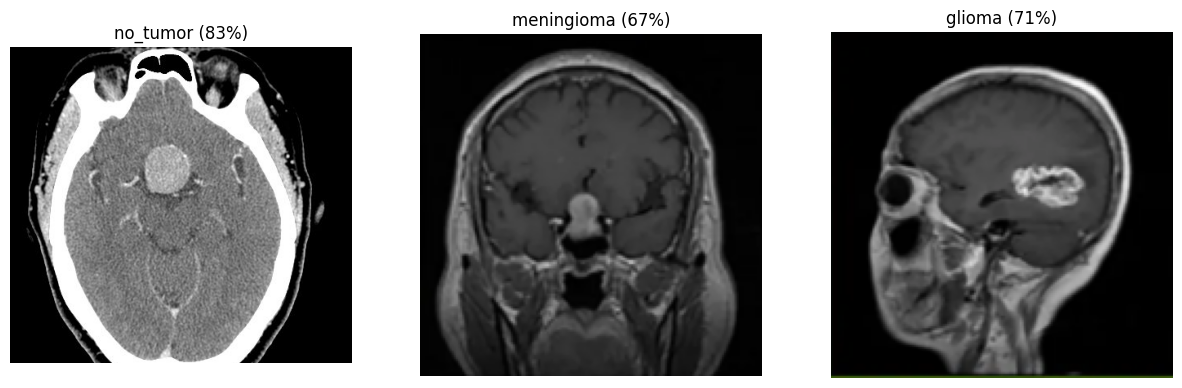

In [18]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

resize = layers.Resizing(224, 224, crop_to_aspect_ratio=True)

plt.figure(figsize=(5 * len(uploaded), 5))
for i, name in enumerate(uploaded):
    img = Image.open(name).convert("RGB")
    x = resize(np.array(img)[None, ...].astype("float32"))

    probs = model.predict(x, verbose=0)[0]
    pred = class_names[np.argmax(probs)]

    plt.subplot(1, len(uploaded), i + 1)
    plt.imshow(img)
    plt.title(f"{pred} ({probs.max():.0%})")
    plt.axis("off")

    print(name)
    for c, p in zip(class_names, probs):
        print(f"  {c:18s} {p:.1%}")
plt.show()

In [14]:
model.save("brain_tumor_model.keras")